# Laboratorio: Conectando una protoboard con la menor cantidad de cable

**Objetivo:** representar los componentes de una protoboard como vértices de un grafo, calcular las distancias entre cada pareja como pesos de las aristas y encontrar un Árbol de Expansión Mínima (MST) mediante el algoritmo de Kruskal.

In [ ]:
# @title Datos del estudiante
nombre_estudiante = ""  # Escriba su nombre
carnet = None           # Escriba su número de carnet

## 1) Descripción del problema

Se tiene una protoboard simplificada de 30 columnas y 10 filas (A–J), en la que están ubicados siete componentes electrónicos: fuente de alimentación (F), LED (L), sensor (S), pulsador (P), buzzer (B), potenciómetro (R) y microcontrolador (M).

Se desea conectar todos los componentes utilizando la menor longitud total de cable posible. Para modelar el problema se utiliza un grafo no dirigido y ponderado: cada componente es un vértice, cada posible cable es una arista y su peso corresponde a la distancia Manhattan entre las posiciones de sus extremos:

Como todos los componentes deben quedar conectados y se busca minimizar la suma de los pesos, se debe encontrar un Árbol de Expansión Mínima utilizando Kruskal. Después se cambia el buzzer de H6 a J20 y se repite el procedimiento para comparar las longitudes totales.

## 2) Requerimientos

### Requerimientos funcionales

**RQF-01. Registrar la distribución inicial de componentes.**

**RQF-02. Representar gráficamente la protoboard.**

**RQF-03. Calcular las distancias entre parejas de componentes.**

**RQF-04. Mostrar todas las conexiones posibles.**

**RQF-05. Calcular el Árbol de Expansión Mínima mediante Kruskal.**

**RQF-06. Calcular e informar la longitud total del cable.**

**RQF-07. Actualizar la posición del buzzer y recalcular el MST.**

### Requerimientos no funcionales

**RQNF-01. No usa librerias de mst directo**

**RQNF-02. Claridad**

**RQNF-03. Integridad** 

**RQNF-04. Visual**

**RQNF-05. Reutilizable** 

## 3) Historias de usuario
### Historia de usuario 1: Crear y calcular una distribución
 
Como usuario del programa, quiero ingresar los componentes y sus posiciones en la protoboard, para obtener una distribución de conexiones optimizada.
 
Ciclo completo:
 
* El usuario inicia el programa.
 
* Ingresa los componentes que necesita conectar.
 
* Asigna una posición a cada componente.
 
* El programa valida que las posiciones sean correctas.
 
* El programa calcula las distancias entre todos los componentes.
 
* Ejecuta el algoritmo de Kruskal.
 
* Muestra el árbol de expansión mínima y la longitud total del cable.
 
* El usuario revisa los resultados y finaliza el proceso.
 
### Historia de usuario 2: Consultar y utilizar los resultados
 
Como usuario del programa, quiero visualizar las conexiones optimizadas y su representación gráfica, para identificar cómo debo realizar el cableado de la protoboard.
 
Ciclo completo:
 
* El usuario inicia el programa.
 
* Carga una distribución previamente ingresada.
 
* Solicita visualizar el resultado de la optimización.
 
* El programa muestra las conexiones seleccionadas.
 
* El programa presenta la representación gráfica del cableado.
 
* El usuario consulta las distancias y la longitud total.
 
* El usuario utiliza la información para realizar el montaje y termina su sesión.
 
### Historia de usuario 3: Modificar una distribución y recalcular
 
Como usuario del programa, quiero modificar la posición de uno o varios componentes, para comprobar cómo afecta el cambio a la longitud total del cableado.
 
Ciclo completo:
 
* El usuario inicia el programa.
 
* Ingresa o recupera una distribución existente.
 
* Selecciona el componente que desea mover.
 
* Introduce su nueva posición.
 
* El programa valida la nueva ubicación.
 
* Se recalculan las distancias y se ejecuta nuevamente Kruskal.
 
* El programa muestra la nueva distribución optimizada.
 
* El usuario compara el resultado anterior con el nuevo.
 
* Decide conservar la nueva distribución o finalizar el programa.

## 4) Diagrama de flujo

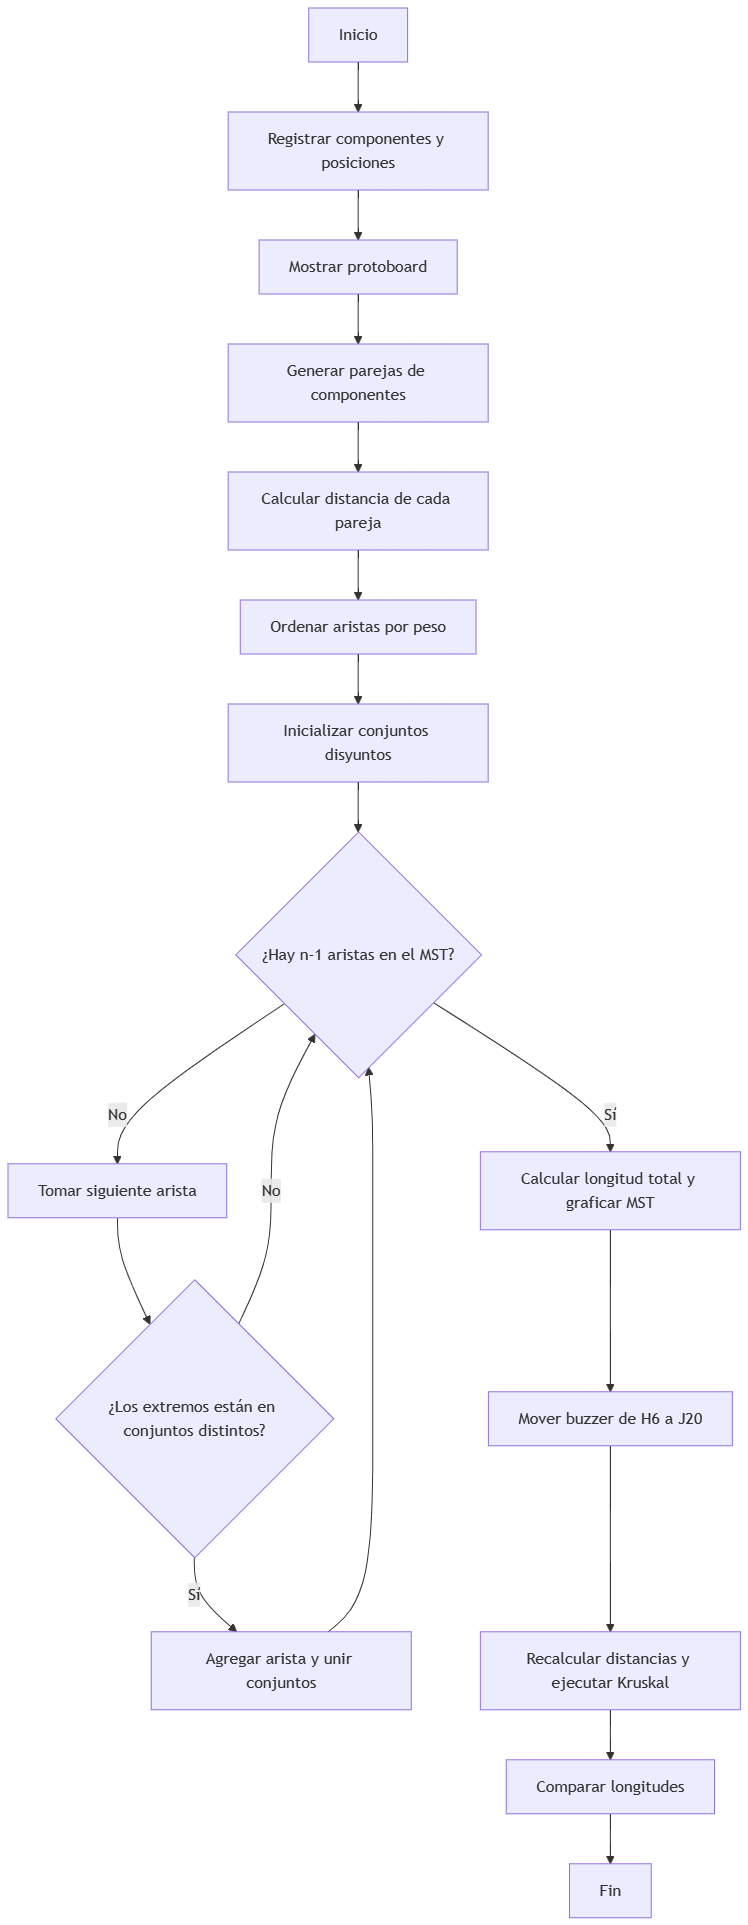

## 5) Análisis de complejidad

Sea V el número de componentes y E el número de conexiones posibles entre ellos.
 
La función de calcular la distancia entre dos componentes tiene una complejidad temporal de O(1), porque realiza únicamente restas y valores absolutos.
 
La construcción del grafo genera todas las parejas posibles de componentes, por lo que tiene una complejidad temporal de O(V²).
 
El ordenamiento de las aristas en el algoritmo de Kruskal tiene una complejidad de O(E log E).
 
La estructura de conjuntos disyuntos (Union-Find), utilizada para detectar y evitar ciclos, permite realizar las operaciones de búsqueda y unión con una complejidad amortizada de O(α(V)), donde α es la función inversa de Ackermann, que crece extremadamente lento.
 
Por lo tanto, la complejidad temporal total del algoritmo de Kruskal es O(E log E). Como el grafo es completo, E = V(V-1)/2, así que la complejidad total del programa está dominada por O(V² log V).
 
La complejidad espacial es O(V²), debido al almacenamiento de todas las conexiones posibles del grafo.
 
Para nuestro caso, con 7 componentes, se generan 21 conexiones posibles y se seleccionan 6 para construir el árbol de expansión mínima.

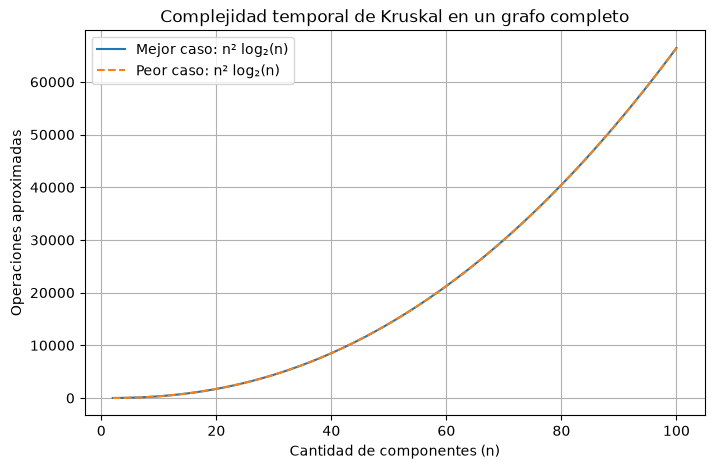

In [5]:
import math
import matplotlib.pyplot as plt

n_valores = list(range(2, 101))
tiempos = [n**2 * math.log2(n) for n in n_valores]

plt.figure(figsize=(8, 5))
plt.plot(n_valores, tiempos, label="Mejor caso: n² log₂(n)")
plt.plot(n_valores, tiempos, linestyle="--", label="Peor caso: n² log₂(n)")
plt.xlabel("Cantidad de componentes (n)")
plt.ylabel("Operaciones aproximadas")
plt.title("Complejidad temporal de Kruskal en un grafo completo")
plt.grid(True)
plt.legend()
plt.show()

## 6) Código funcional

La implementación utiliza únicamente Python y Matplotlib para construir los datos y visualizar la protoboard. El algoritmo de Kruskal está implementado manualmente mediante conjuntos disyuntos; no se utiliza ninguna función externa para obtener el MST.

POSICIONES INICIALES
F (Fuente): A3
L (LED): C8
S (Sensor): B16
P (Pulsador): D24
B (Buzzer): H6
R (Potenciómetro): I15
M (Microcontrolador): G25


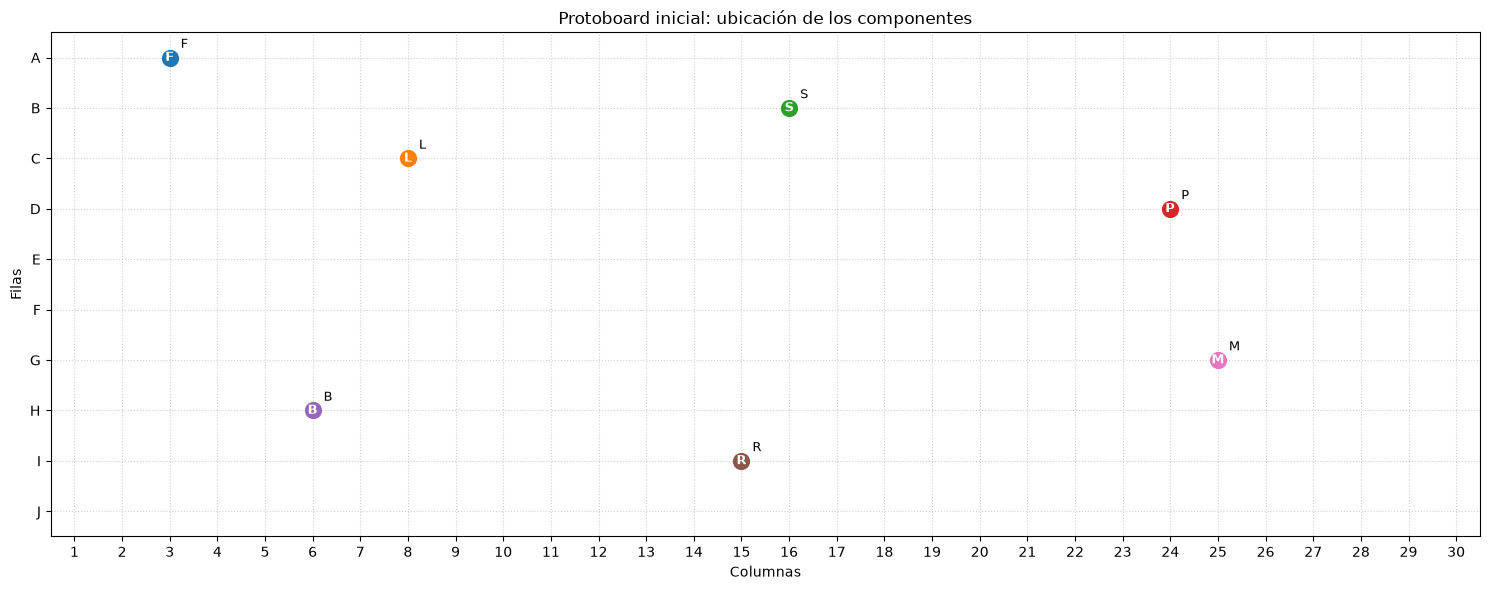


TODAS LAS CONEXIONES POSIBLES
P (Pulsador) - M (Microcontrolador) = 4 unidades
F (Fuente) - L (LED) = 7 unidades
L (LED) - B (Buzzer) = 7 unidades
S (Sensor) - R (Potenciómetro) = 8 unidades
L (LED) - S (Sensor) = 9 unidades
B (Buzzer) - R (Potenciómetro) = 10 unidades
F (Fuente) - B (Buzzer) = 10 unidades
S (Sensor) - P (Pulsador) = 10 unidades
R (Potenciómetro) - M (Microcontrolador) = 12 unidades
L (LED) - R (Potenciómetro) = 13 unidades
F (Fuente) - S (Sensor) = 14 unidades
P (Pulsador) - R (Potenciómetro) = 14 unidades
S (Sensor) - M (Microcontrolador) = 14 unidades
S (Sensor) - B (Buzzer) = 16 unidades
L (LED) - P (Pulsador) = 17 unidades
B (Buzzer) - M (Microcontrolador) = 20 unidades
F (Fuente) - R (Potenciómetro) = 20 unidades
L (LED) - M (Microcontrolador) = 21 unidades
P (Pulsador) - B (Buzzer) = 22 unidades
F (Fuente) - P (Pulsador) = 24 unidades
F (Fuente) - M (Microcontrolador) = 28 unidades


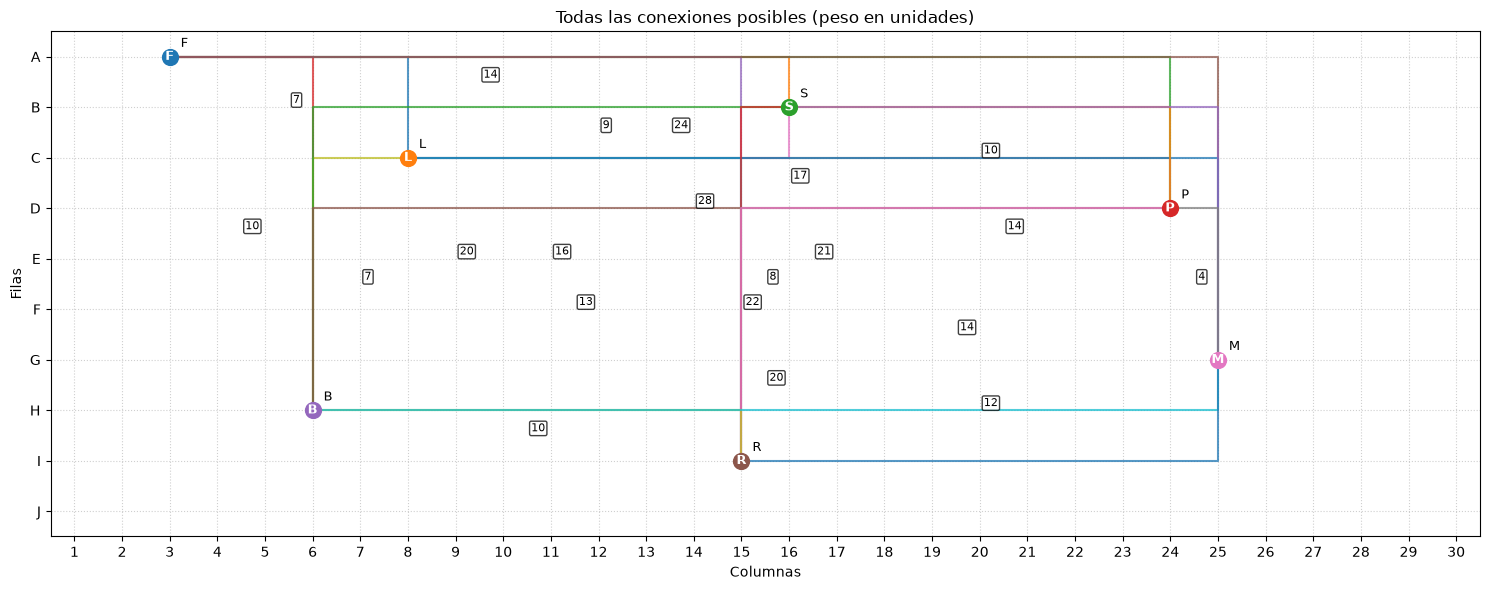


========== MST ORIGINAL ==========
Cable 1: P - M = 4 unidades
Cable 2: F - L = 7 unidades
Cable 3: L - B = 7 unidades
Cable 4: S - R = 8 unidades
Cable 5: L - S = 9 unidades
Cable 6: S - P = 10 unidades
Longitud total de cable: 45 unidades
Cantidad de conexiones: 6


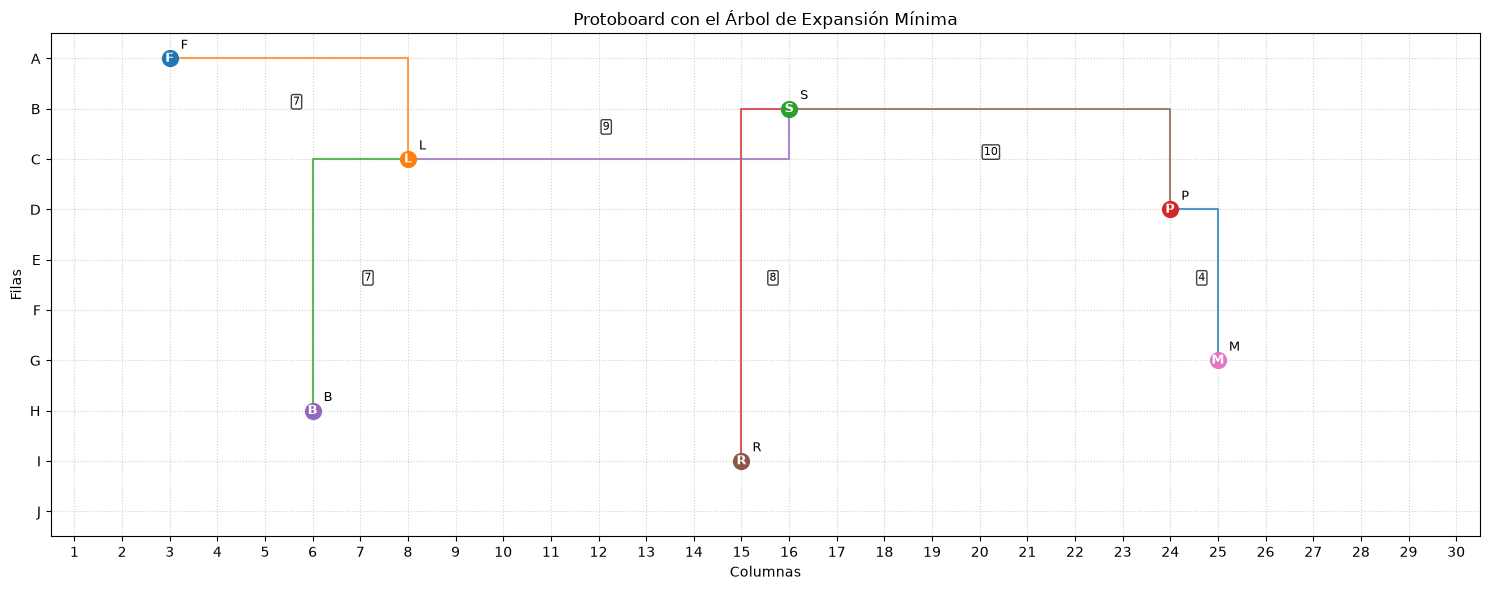


CAMBIO DE DISTRIBUCIÓN
Buzzer: H6 -> J20

========== MST DESPUÉS DEL CAMBIO ==========
Cable 1: P - M = 4 unidades
Cable 2: B - R = 6 unidades
Cable 3: F - L = 7 unidades
Cable 4: S - R = 8 unidades
Cable 5: B - M = 8 unidades
Cable 6: L - S = 9 unidades
Longitud total de cable: 42 unidades
Cantidad de conexiones: 6


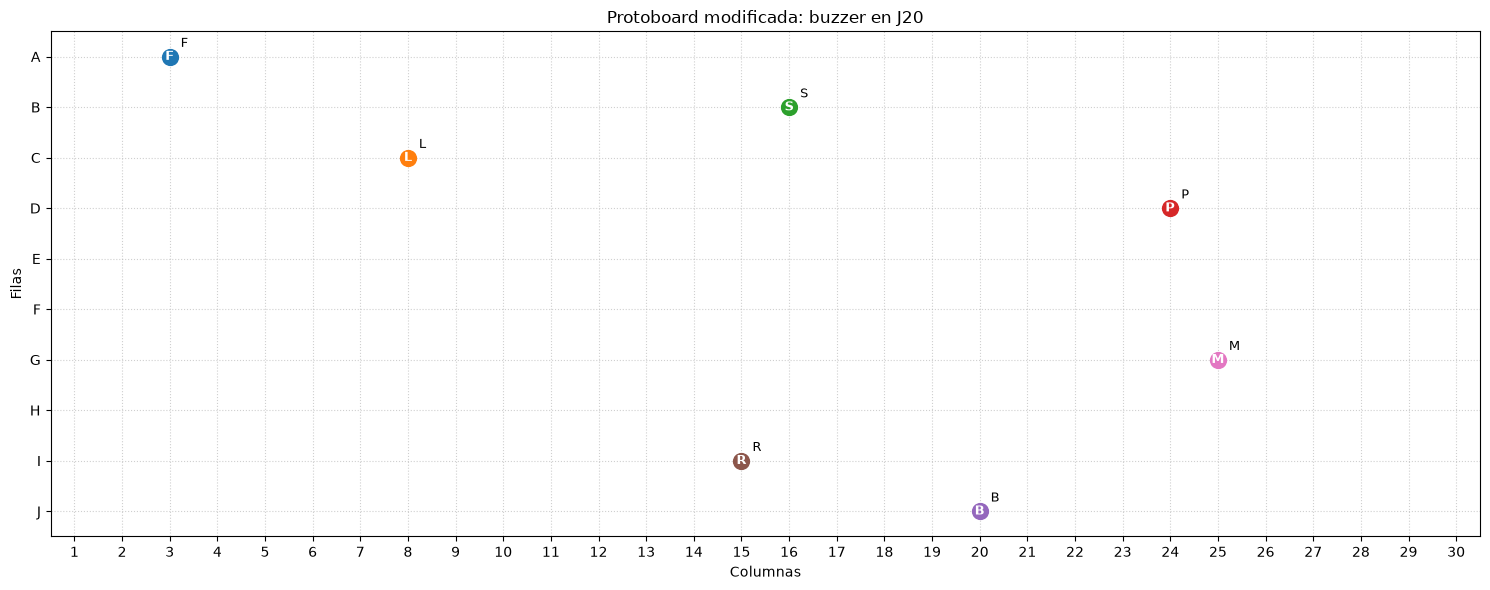

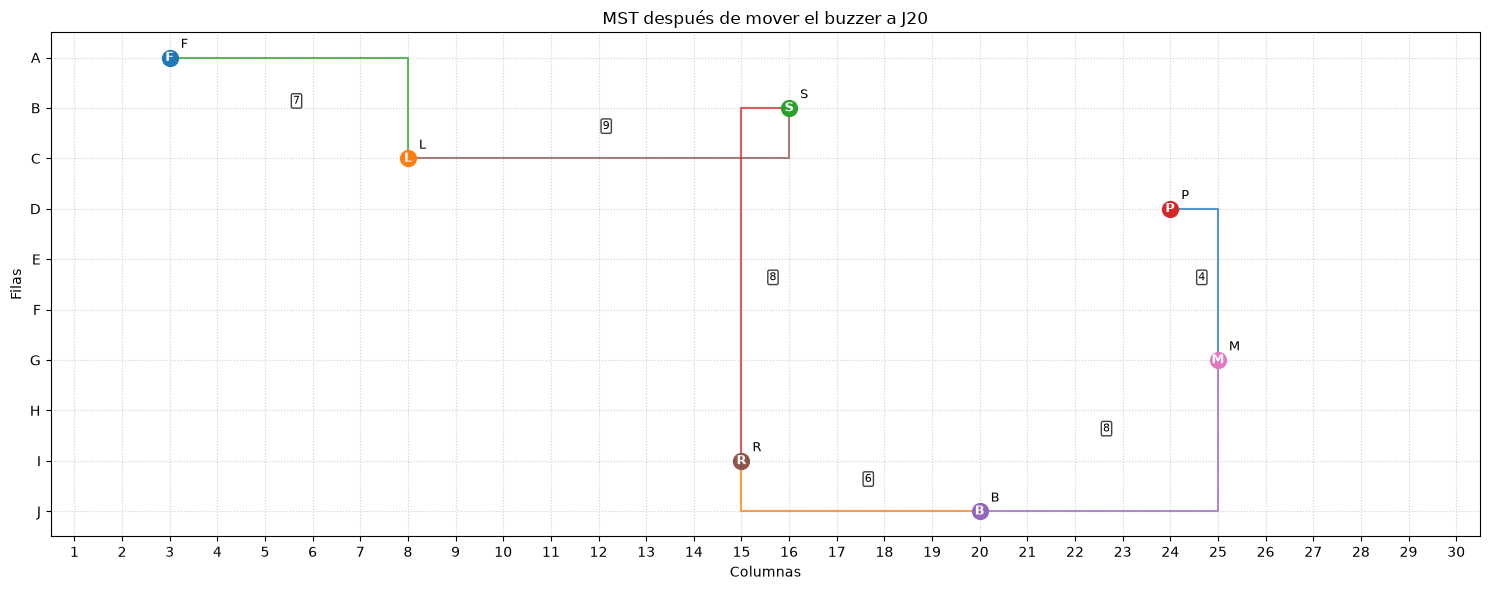


========== COMPARACIÓN ==========
MST original: 45 unidades
MST modificado: 42 unidades
La longitud disminuyó en 3 unidades.


In [1]:
import matplotlib.pyplot as plt
from itertools import combinations

# Filas de la protoboard convertidas a coordenadas numéricas.
FILAS = {letra: numero for numero, letra in enumerate("ABCDEFGHIJ", start=1)}

# Distribución inicial: identificador -> (columna, fila_numérica).
componentes_iniciales = {
    "F": (3, FILAS["A"]),    # Fuente de alimentación: A3
    "L": (8, FILAS["C"]),    # LED: C8
    "S": (16, FILAS["B"]),   # Sensor: B16
    "P": (24, FILAS["D"]),   # Pulsador: D24
    "B": (6, FILAS["H"]),    # Buzzer: H6
    "R": (15, FILAS["I"]),   # Potenciómetro: I15
    "M": (25, FILAS["G"])    # Microcontrolador: G25
}

nombres = {
    "F": "Fuente",
    "L": "LED",
    "S": "Sensor",
    "P": "Pulsador",
    "B": "Buzzer",
    "R": "Potenciómetro",
    "M": "Microcontrolador"
}


def posicion_texto(posicion):
    """Convierte (columna, fila_numérica) a una posición como A3."""
    columna, fila = posicion
    letra = next(letra for letra, numero in FILAS.items() if numero == fila)
    return f"{letra}{columna}"


def validar_componentes(componentes):
    """Comprueba que cada componente esté dentro de la protoboard."""
    for identificador, (columna, fila) in componentes.items():
        if not (1 <= columna <= 30 and 1 <= fila <= 10):
            raise ValueError(f"Posición inválida para {identificador}: "
                             f"{posicion_texto((columna, fila))}")


def calcular_distancia(pos1, pos2):
    """Calcula la distancia entre dos posiciones."""
    x1, y1 = pos1
    x2, y2 = pos2
    return abs(x1 - x2) + abs(y1 - y2)


def construir_grafo(componentes):
    """Genera todas las aristas posibles con sus pesos calculados."""
    validar_componentes(componentes)
    aristas = []
    for a, b in combinations(componentes.keys(), 2):
        peso = calcular_distancia(componentes[a], componentes[b])
        aristas.append((peso, a, b))
    return aristas


def encontrar(padre, vertice):
    """Encuentra la raíz de un conjunto aplicando compresión de caminos."""
    if padre[vertice] != vertice:
        padre[vertice] = encontrar(padre, padre[vertice])
    return padre[vertice]


def unir(padre, rango, a, b):
    """Une dos conjuntos. Devuelve False si ya estaban unidos."""
    raiz_a = encontrar(padre, a)
    raiz_b = encontrar(padre, b)

    if raiz_a == raiz_b:
        return False

    if rango[raiz_a] < rango[raiz_b]:
        padre[raiz_a] = raiz_b
    elif rango[raiz_a] > rango[raiz_b]:
        padre[raiz_b] = raiz_a
    else:
        padre[raiz_b] = raiz_a
        rango[raiz_a] += 1

    return True


def kruskal(componentes, aristas):
    """Obtiene manualmente el MST mediante el algoritmo de Kruskal."""
    padre = {vertice: vertice for vertice in componentes}
    rango = {vertice: 0 for vertice in componentes}
    mst = []

    aristas_ordenadas = sorted(aristas, key=lambda arista: arista[0])

    for peso, a, b in aristas_ordenadas:
        # Solo se agrega la arista si no crea un ciclo.
        if unir(padre, rango, a, b):
            mst.append((peso, a, b))

        if len(mst) == len(componentes) - 1:
            break

    if len(mst) != len(componentes) - 1:
        raise ValueError("No fue posible conectar todos los componentes.")

    return mst


def mostrar_aristas(aristas, titulo):
    """Imprime las conexiones y sus longitudes."""
    print(f"\n{titulo}")
    for peso, a, b in sorted(aristas):
        print(f"{a} ({nombres[a]}) - {b} ({nombres[b]}) = {peso} unidades")


def dibujar_protoboard(componentes, aristas=None, titulo="Protoboard",
                       mostrar_pesos=True):
    """Dibuja la cuadrícula y las conexiones indicadas."""
    if aristas is None:
        aristas = []

    fig, ax = plt.subplots(figsize=(15, 6))

    # Cuadrícula de 30 columnas por 10 filas.
    ax.set_xlim(0.5, 30.5)
    ax.set_ylim(10.5, 0.5)  # La fila A queda arriba.
    ax.set_xticks(range(1, 31))
    ax.set_yticks(range(1, 11))
    ax.set_yticklabels(list("ABCDEFGHIJ"))
    ax.set_xlabel("Columnas")
    ax.set_ylabel("Filas")
    ax.set_title(titulo)
    ax.grid(True, linestyle=":", alpha=0.6)

    # Dibujar las conexiones detrás de los componentes.
    for peso, a, b in aristas:
        x1, y1 = componentes[a]
        x2, y2 = componentes[b]
        ax.plot([x1, x2, x2], [y1, y1, y2], linewidth=1.5, alpha=0.75)

        if mostrar_pesos:
            xm = (x1 + x2) / 2
            ym = (y1 + y2) / 2
            ax.annotate(str(peso), (xm, ym), fontsize=8,
                        xytext=(3, 3), textcoords="offset points",
                        bbox=dict(boxstyle="round,pad=0.15",
                                  fc="white", alpha=0.75))

    # Dibujar los vértices y sus identificadores.
    for identificador, (x, y) in componentes.items():
        ax.scatter(x, y, s=130, zorder=3)
        ax.annotate(identificador, (x, y), ha="center", va="center",
                    fontsize=9, fontweight="bold", color="white", zorder=4)
        ax.annotate(f" {identificador}", (x, y), xytext=(5, 7),
                    textcoords="offset points", fontsize=9)

    plt.tight_layout()
    plt.show()


def mostrar_resultado(mst, titulo):
    """Muestra las conexiones del MST y su longitud total."""
    print(f"\n========== {titulo} ==========")
    for numero, (peso, a, b) in enumerate(mst, start=1):
        print(f"Cable {numero}: {a} - {b} = {peso} unidades")

    total = sum(peso for peso, _, _ in mst)
    print(f"Longitud total de cable: {total} unidades")
    print(f"Cantidad de conexiones: {len(mst)}")
    return total


# -------------------- DISTRIBUCIÓN INICIAL --------------------

print("POSICIONES INICIALES")
for identificador, posicion in componentes_iniciales.items():
    print(f"{identificador} ({nombres[identificador]}): "
          f"{posicion_texto(posicion)}")

# Punto 1: protoboard sin cables.
dibujar_protoboard(componentes_iniciales,
                   titulo="Protoboard inicial: ubicación de los componentes")

# Punto 2 y 3: grafo completo y todas sus conexiones.
aristas_iniciales = construir_grafo(componentes_iniciales)
mostrar_aristas(aristas_iniciales, "TODAS LAS CONEXIONES POSIBLES")

dibujar_protoboard(componentes_iniciales, aristas_iniciales,
                   titulo="Todas las conexiones posibles (peso en unidades)")

# Punto 4 y 5: calcular y mostrar el MST.
mst_inicial = kruskal(componentes_iniciales, aristas_iniciales)
total_inicial = mostrar_resultado(mst_inicial, "MST ORIGINAL")

dibujar_protoboard(componentes_iniciales, mst_inicial,
                   titulo="Protoboard con el Árbol de Expansión Mínima")


# -------------------- CAMBIO DE POSICIÓN DEL BUZZER --------------------

componentes_modificados = componentes_iniciales.copy()
componentes_modificados["B"] = (20, FILAS["J"])  # Nueva posición: J20

print("\nCAMBIO DE DISTRIBUCIÓN")
print("Buzzer: H6 -> J20")

aristas_modificadas = construir_grafo(componentes_modificados)
mst_modificado = kruskal(componentes_modificados, aristas_modificadas)
total_modificado = mostrar_resultado(mst_modificado, "MST DESPUÉS DEL CAMBIO")

dibujar_protoboard(componentes_modificados,
                   titulo="Protoboard modificada: buzzer en J20")
dibujar_protoboard(componentes_modificados, mst_modificado,
                   titulo="MST después de mover el buzzer a J20")

# Punto 6: comparar las longitudes.
diferencia = total_modificado - total_inicial
print("\n========== COMPARACIÓN ==========")
print(f"MST original: {total_inicial} unidades")
print(f"MST modificado: {total_modificado} unidades")

if diferencia > 0:
    print(f"La longitud aumentó en {diferencia} unidades.")
elif diferencia < 0:
    print(f"La longitud disminuyó en {abs(diferencia)} unidades.")
else:
    print("La longitud total permaneció igual.")

## 7) Tests aplicados

Se comprueba que:
- Se generen 21 conexiones posibles para siete componentes: 7·6/2 = 21.
- El MST tenga exactamente seis conexiones.
- El MST conecte los siete componentes.
- Cada peso corresponda a la distancia Manhattan entre las posiciones.
- La suma de los pesos sea igual a la longitud total calculada.
- El cambio del buzzer actualice su posición a J20 y permita calcular un nuevo MST.

In [2]:
# Pruebas de la distribución inicial
assert len(componentes_iniciales) == 7
assert len(aristas_iniciales) == 21
assert len(mst_inicial) == len(componentes_iniciales) - 1

# Distancia de ejemplo del enunciado: F=A3 y L=C8.
assert calcular_distancia(componentes_iniciales["F"],
                          componentes_iniciales["L"]) == 7

# Comprobar que cada arista del MST tiene el peso correcto.
for peso, a, b in mst_inicial:
    assert peso == calcular_distancia(componentes_iniciales[a],
                                      componentes_iniciales[b])

assert total_inicial == sum(peso for peso, _, _ in mst_inicial)

# Pruebas después de mover el buzzer.
assert posicion_texto(componentes_modificados["B"]) == "J20"
assert len(aristas_modificadas) == 21
assert len(mst_modificado) == len(componentes_modificados) - 1
assert total_modificado == sum(peso for peso, _, _ in mst_modificado)
print("Todo correcto")


Todo correcto
